In [2]:
import pandas as pd
import numpy as np

def parse_and_process_data(file_path):
    # --- 1. Robust CSV Parsing ---
    # Since 'tags' contains commas but isn't quoted, we can't use standard pd.read_csv.
    # We parse manually assuming the structure: 
    # [Fixed 6 Cols] ... [Variable Tags] ... [Fixed 1 Col]
    
    data = []
    
    with open(file_path, 'r', encoding='utf-8') as f:
        header = f.readline() # Skip header
        
        for line in f:
            line = line.strip()
            if not line: continue
            
            parts = line.split(',')
            
            # Extract fixed columns from the start
            handle = parts[0]
            contest_id = parts[1]
            problem_index = parts[2]
            problem_name = parts[3]
            rating = parts[4]
            old_rating = parts[5]
            
            # Extract fixed column from the end
            solve_time = parts[-1]
            
            # Everything in between is the tags list
            # We join them with a pipe '|' or keep as comma string to treat as one column
            tags_raw = parts[6:-1]
            tags = ",".join(tags_raw) # Re-joining as a single string
            
            data.append([
                handle, contest_id, problem_index, problem_name, 
                rating, old_rating, tags, solve_time
            ])

    # Create DataFrame
    columns = ['handle', 'contestId', 'problemIndex', 'problemName', 'rating', 'oldRating', 'tags', 'solveTime']
    df = pd.DataFrame(data, columns=columns)

    # --- 2. Type Conversion ---
    # Convert numeric columns to proper types
    df['contestId'] = pd.to_numeric(df['contestId'])
    df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
    df['oldRating'] = pd.to_numeric(df['oldRating'], errors='coerce')
    df['solveTime'] = pd.to_numeric(df['solveTime'])

    # --- 3. Calculate timeDiff ---
    # Sort by handle, contest, and solveTime to ensure correct order of solving
    df = df.sort_values(by=['handle', 'contestId', 'solveTime'])

    # Group by handle and contestId
    # The timeDiff is solveTime of current problem - solveTime of previous problem
    # For the first problem in a contest, timeDiff is equal to solveTime (time since start)
    df['prev_solveTime'] = df.groupby(['handle', 'contestId'])['solveTime'].shift(1)
    df['prev_solveTime'] = df['prev_solveTime'].fillna(0) # Start time is 0
    
    df['timeDiff'] = df['solveTime'] - df['prev_solveTime']
    
    # Drop the helper column
    df.drop(columns=['prev_solveTime'], inplace=True)

    return df

# Usage
# Replace 'raw_data.csv' with your actual filename
df_clean = parse_and_process_data('data.csv')
df_clean.to_csv('processed_data_with_metrics.csv', index=False)
print(df_clean[['handle', 'contestId', 'problemIndex', 'tags', 'solveTime', 'timeDiff']].head(10))

                  handle  contestId problemIndex  \
74643           ---.---.       2122            A   
66718    ---hariharan---       2122            A   
66717    ---hariharan---       2122            B   
25879    ---hariharan---       2124            A   
25878    ---hariharan---       2124            B   
67288       --Accepted--       2122            A   
67287       --Accepted--       2122            B   
27538       --Accepted--       2124            A   
27537       --Accepted--       2124            B   
136826  --JuliusCaesar--       2114            A   

                                  tags  solveTime  timeDiff  
74643   constructive algorithms,greedy        688     688.0  
66718   constructive algorithms,greedy        915     915.0  
66717                      greedy,math       2738    1823.0  
25879                  greedy,sortings       1119    1119.0  
25878                           greedy       4141    3022.0  
67288   constructive algorithms,greedy        411     4

In [6]:
df_clean.head()

df1 = df_clean.copy()

=== EDA FOR TIME DIFFERENCE PREDICTION ===
Dataset Shape: (158201, 9)

1. DATA QUALITY ASSESSMENT
Missing Values:
           Missing Count  Missing %
oldRating           1014       0.64

Target Variable (timeDiff) Analysis:
- Non-null count: 158201
- Null count: 0
- Data availability: 100.0%

2. TARGET VARIABLE DISTRIBUTION
Clean dataset size: 158201 rows

TimeDiff Statistics (in minutes):
count    158201.000000
mean         26.522064
std          23.603760
min           0.000000
25%           9.566667
50%          18.516667
75%          35.866667
max         177.800000
Name: timeDiff_min, dtype: float64
Extreme outliers (>Q3+1.5*IQR): 8472 (5.4%)


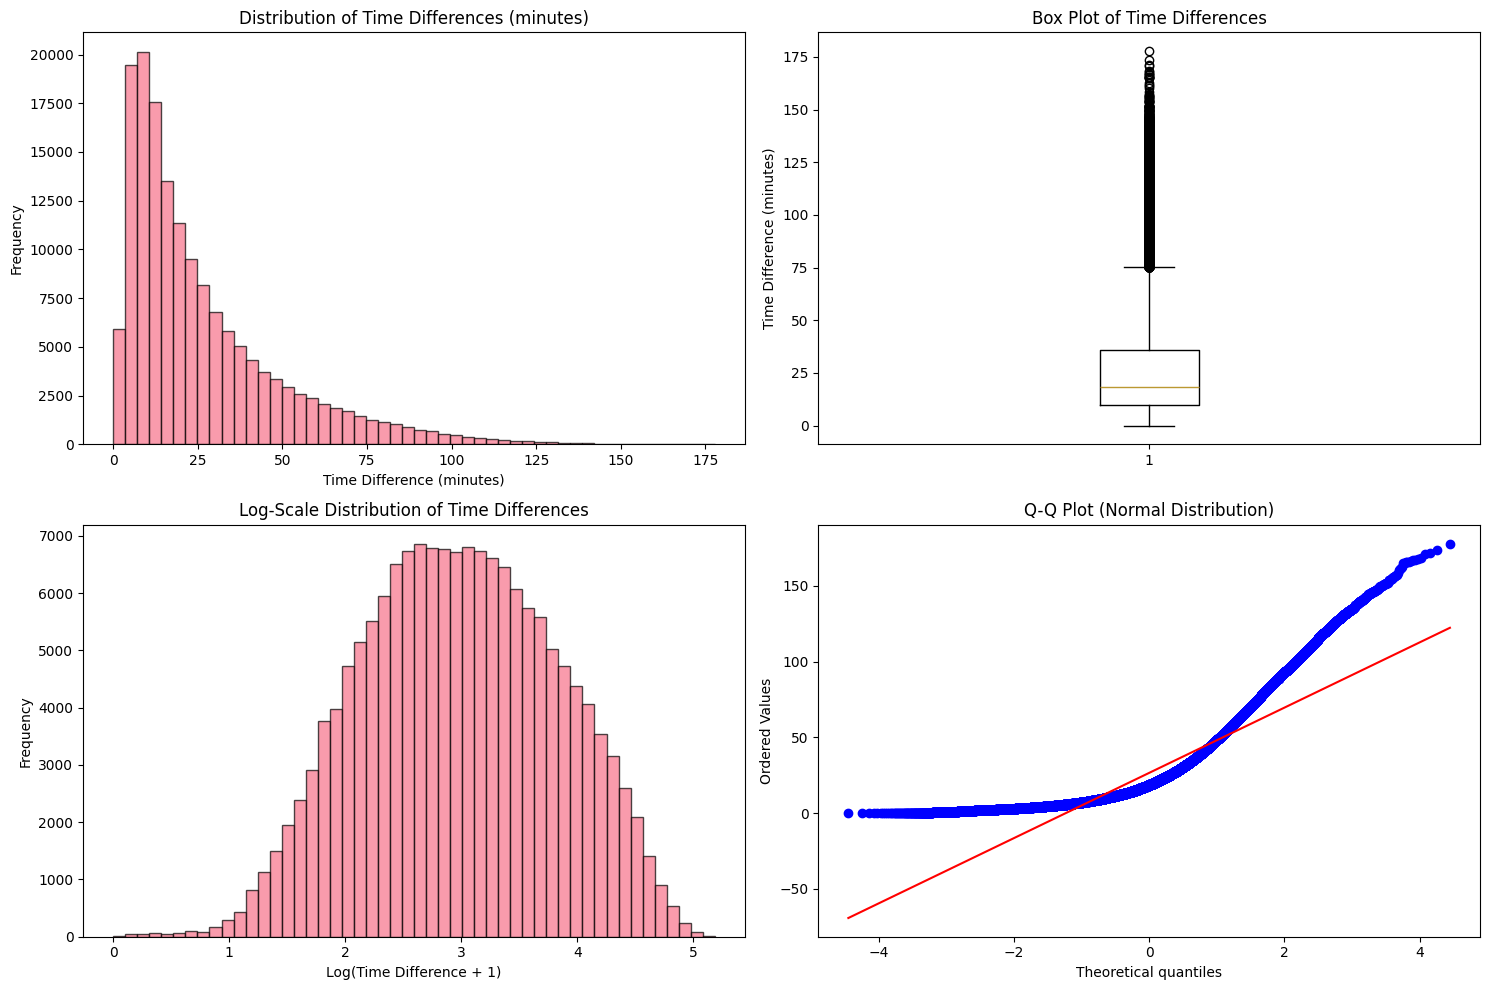


4. FEATURE AVAILABILITY AND QUALITY
Feature Analysis:

rating:
  type: numerical
  availability: 100.0%
  unique_values: 22
  mean: 1071.884501362191
  std: 319.5953418204504

oldRating:
  type: numerical
  availability: 99.4%
  unique_values: 2333
  mean: 1313.7494576523504
  std: 447.9346110705514

solveTime:
  type: numerical
  availability: 100.0%
  unique_values: 9650
  mean: 2630.6490098039835
  std: 2180.7528750659753

handle:
  type: categorical
  availability: 100.0%
  unique_values: 35186
  most_frequent: alpha_6124

contestId:
  type: categorical
  availability: 100.0%
  unique_values: 6
  most_frequent: 2114

problemIndex:
  type: categorical
  availability: 100.0%
  unique_values: 11
  most_frequent: A

problemName:
  type: categorical
  availability: 100.0%
  unique_values: 42
  most_frequent: Greedy Grid

tags:
  type: text
  availability: 100.0%
  unique_values: 40
  avg_tags_per_problem: 2.558258165245479

5. CORRELATION ANALYSIS


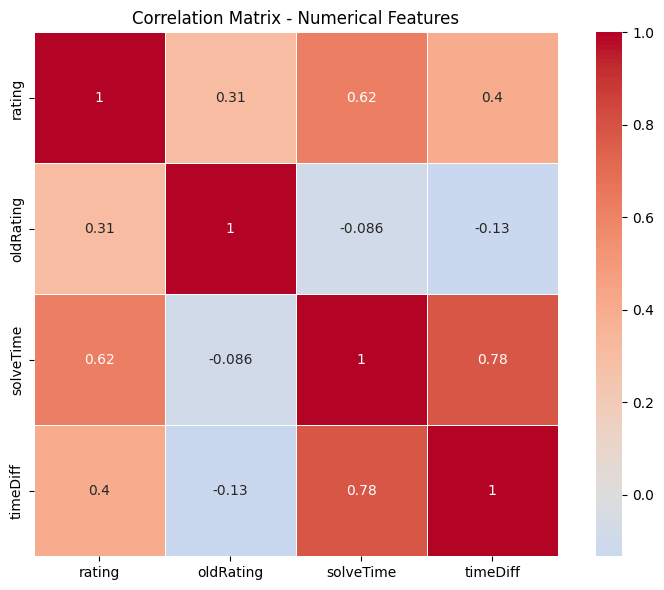

Correlations with timeDiff:
  solveTime: 0.785
  rating: 0.401
  oldRating: -0.133

6. FEATURE RELATIONSHIPS WITH TARGET


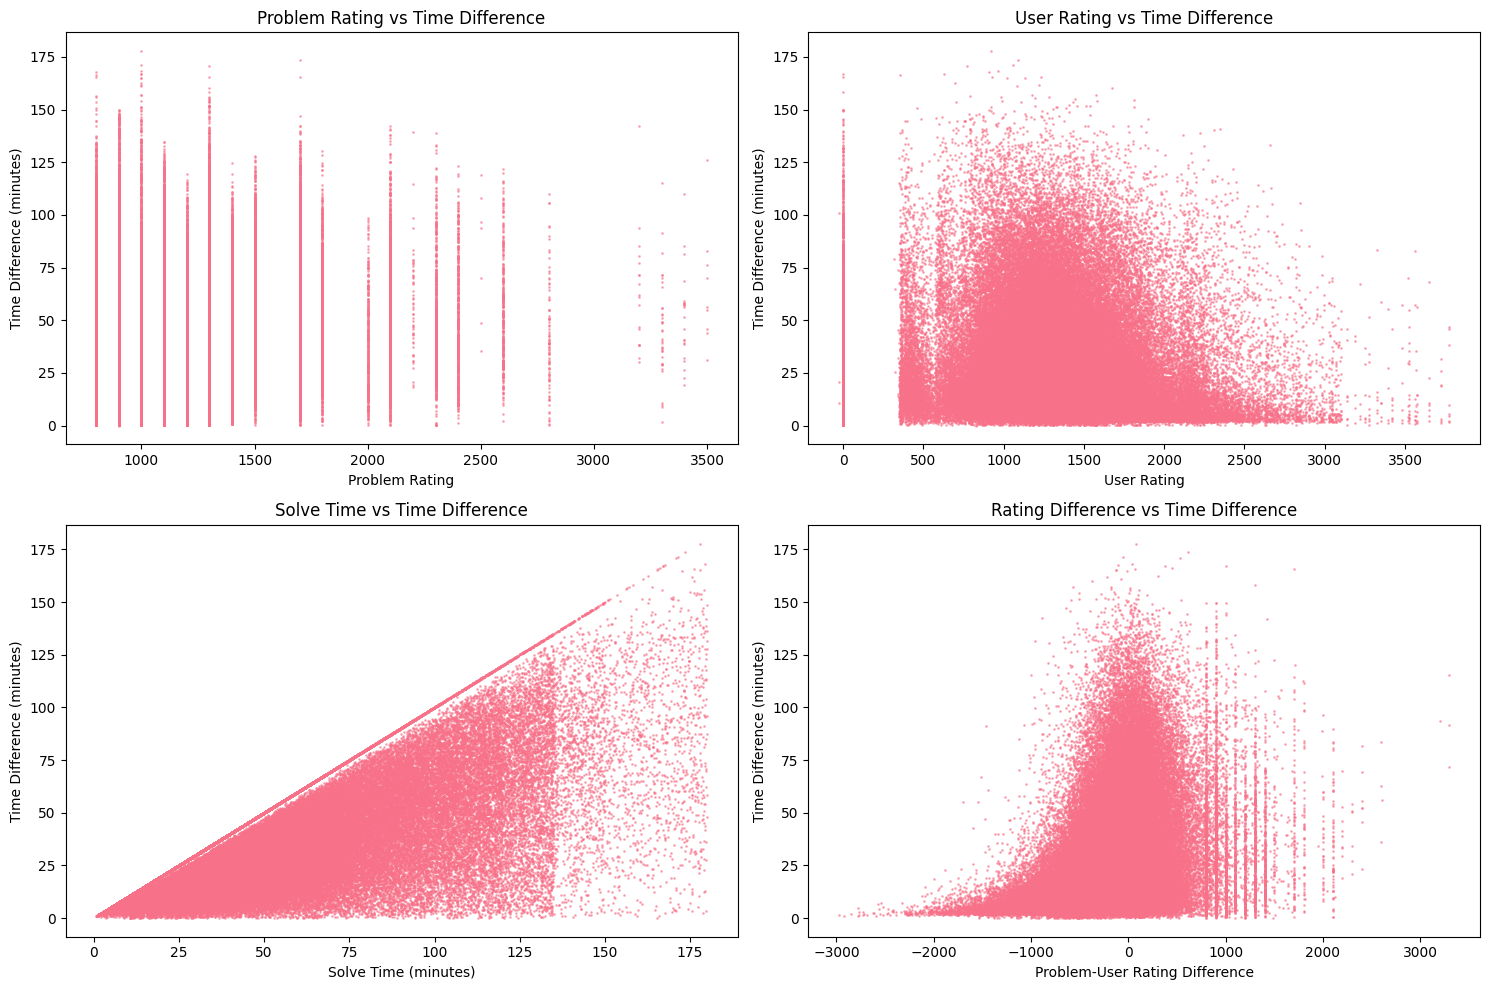


7. ML READINESS ASSESSMENT
✓ Sufficient samples (>1000): Yes (158201 samples)
✓ rating completeness (>80%): 100.0%
✓ oldRating completeness (>80%): 99.4%
✓ solveTime completeness (>80%): 100.0%
✓ tags completeness (>80%): 100.0%
✓ Target variable range: 177.8 minutes
✓ Target variable variance: 557.1
✓ Minimum class percentage (target binned): 20.0%

8. RECOMMENDATIONS FOR ML MODEL
STRENGTHS:
✓ Good sample size for training
✓ Key rating features have good completeness
✓ Some meaningful correlations exist

CHALLENGES:
⚠ Many extreme outliers - consider additional outlier removal

RECOMMENDED PREPROCESSING:
1. Apply log transformation to target variable
2. Handle remaining outliers (beyond current filtering)
3. Feature engineering: rating differences, user experience metrics
4. One-hot encode tags or use text embeddings
5. Create temporal features from contest timing
6. Consider user-specific features (average solve times, etc.)

✓ OVERALL ASSESSMENT: GOOD
The dataset appears suitable f

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('default')
sns.set_palette("husl")

print("=== EDA FOR TIME DIFFERENCE PREDICTION ===")
print(f"Dataset Shape: {df1.shape}")

# 1. DATA QUALITY ASSESSMENT
print("\n1. DATA QUALITY ASSESSMENT")
print("=" * 50)

# Missing values analysis
print("Missing Values:")
missing_info = df1.isnull().sum()
missing_pct = (missing_info / len(df1) * 100).round(2)
missing_df = pd.DataFrame({
    'Missing Count': missing_info,
    'Missing %': missing_pct
}).sort_values('Missing Count', ascending=False)
print(missing_df[missing_df['Missing Count'] > 0])

# Target variable (timeDiff) analysis
print(f"\nTarget Variable (timeDiff) Analysis:")
print(f"- Non-null count: {df1['timeDiff'].count()}")
print(f"- Null count: {df1['timeDiff'].isnull().sum()}")
print(f"- Data availability: {(df1['timeDiff'].count() / len(df1) * 100):.1f}%")

# 2. TARGET VARIABLE DISTRIBUTION
print("\n2. TARGET VARIABLE DISTRIBUTION")
print("=" * 50)

# Convert to minutes for better interpretability
df1_analysis = df1.copy()
df1_analysis['timeDiff_min'] = df1_analysis['timeDiff'] / 60

# Remove rows where timeDiff is null for analysis
df_clean = df1_analysis.dropna(subset=['timeDiff'])

print(f"Clean dataset size: {len(df_clean)} rows")
print(f"\nTimeDiff Statistics (in minutes):")
print(df_clean['timeDiff_min'].describe())

# Check for extreme outliers
Q1 = df_clean['timeDiff_min'].quantile(0.25)
Q3 = df_clean['timeDiff_min'].quantile(0.75)
IQR = Q3 - Q1
outlier_threshold = Q3 + 1.5 * IQR
extreme_outliers = (df_clean['timeDiff_min'] > outlier_threshold).sum()
print(f"Extreme outliers (>Q3+1.5*IQR): {extreme_outliers} ({extreme_outliers/len(df_clean)*100:.1f}%)")

# 3. VISUALIZATION OF TARGET VARIABLE
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Histogram
axes[0,0].hist(df_clean['timeDiff_min'], bins=50, alpha=0.7, edgecolor='black')
axes[0,0].set_title('Distribution of Time Differences (minutes)')
axes[0,0].set_xlabel('Time Difference (minutes)')
axes[0,0].set_ylabel('Frequency')

# Box plot
axes[0,1].boxplot(df_clean['timeDiff_min'])
axes[0,1].set_title('Box Plot of Time Differences')
axes[0,1].set_ylabel('Time Difference (minutes)')

# Log scale histogram (to better see distribution)
axes[1,0].hist(np.log1p(df_clean['timeDiff_min']), bins=50, alpha=0.7, edgecolor='black')
axes[1,0].set_title('Log-Scale Distribution of Time Differences')
axes[1,0].set_xlabel('Log(Time Difference + 1)')
axes[1,0].set_ylabel('Frequency')

# QQ plot for normality
stats.probplot(df_clean['timeDiff_min'], dist="norm", plot=axes[1,1])
axes[1,1].set_title('Q-Q Plot (Normal Distribution)')

plt.tight_layout()
plt.show()

# 4. FEATURE AVAILABILITY AND QUALITY
print("\n4. FEATURE AVAILABILITY AND QUALITY")
print("=" * 50)

features_analysis = {}

# Numerical features
num_features = ['rating', 'oldRating', 'solveTime']
for feature in num_features:
    non_null = df_clean[feature].count()
    total = len(df_clean)
    availability = (non_null / total * 100)
    
    features_analysis[feature] = {
        'type': 'numerical',
        'availability': f"{availability:.1f}%",
        'unique_values': df_clean[feature].nunique(),
        'mean': df_clean[feature].mean(),
        'std': df_clean[feature].std()
    }

# Categorical features
cat_features = ['handle', 'contestId', 'problemIndex', 'problemName']
for feature in cat_features:
    non_null = df_clean[feature].count()
    total = len(df_clean)
    availability = (non_null / total * 100)
    
    features_analysis[feature] = {
        'type': 'categorical',
        'availability': f"{availability:.1f}%",
        'unique_values': df_clean[feature].nunique(),
        'most_frequent': df_clean[feature].mode().iloc[0] if len(df_clean[feature].mode()) > 0 else 'N/A'
    }

# Tags feature
tags_available = df_clean['tags'].notna().sum()
features_analysis['tags'] = {
    'type': 'text',
    'availability': f"{(tags_available/len(df_clean)*100):.1f}%",
    'unique_values': df_clean['tags'].nunique(),
    'avg_tags_per_problem': df_clean['tags'].str.count(',').mean() + 1
}

print("Feature Analysis:")
for feature, info in features_analysis.items():
    print(f"\n{feature}:")
    for key, value in info.items():
        print(f"  {key}: {value}")

# 5. CORRELATION ANALYSIS
print("\n5. CORRELATION ANALYSIS")
print("=" * 50)

# Numerical features correlation with target
numerical_cols = ['rating', 'oldRating', 'solveTime', 'timeDiff']
corr_matrix = df_clean[numerical_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, 
            square=True, linewidths=0.5)
plt.title('Correlation Matrix - Numerical Features')
plt.tight_layout()
plt.show()

print("Correlations with timeDiff:")
correlations = corr_matrix['timeDiff'].drop('timeDiff').sort_values(key=abs, ascending=False)
for feature, corr in correlations.items():
    print(f"  {feature}: {corr:.3f}")

# 6. RELATIONSHIP VISUALIZATIONS
print("\n6. FEATURE RELATIONSHIPS WITH TARGET")
print("=" * 50)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Problem rating vs timeDiff
axes[0,0].scatter(df_clean['rating'], df_clean['timeDiff_min'], alpha=0.5, s=1)
axes[0,0].set_xlabel('Problem Rating')
axes[0,0].set_ylabel('Time Difference (minutes)')
axes[0,0].set_title('Problem Rating vs Time Difference')

# User rating vs timeDiff
axes[0,1].scatter(df_clean['oldRating'], df_clean['timeDiff_min'], alpha=0.5, s=1)
axes[0,1].set_xlabel('User Rating')
axes[0,1].set_ylabel('Time Difference (minutes)')
axes[0,1].set_title('User Rating vs Time Difference')

# Solve time vs timeDiff
axes[1,0].scatter(df_clean['solveTime']/60, df_clean['timeDiff_min'], alpha=0.5, s=1)
axes[1,0].set_xlabel('Solve Time (minutes)')
axes[1,0].set_ylabel('Time Difference (minutes)')
axes[1,0].set_title('Solve Time vs Time Difference')

# Rating difference vs timeDiff
df_clean['rating_diff'] = df_clean['rating'] - df_clean['oldRating']
axes[1,1].scatter(df_clean['rating_diff'], df_clean['timeDiff_min'], alpha=0.5, s=1)
axes[1,1].set_xlabel('Problem-User Rating Difference')
axes[1,1].set_ylabel('Time Difference (minutes)')
axes[1,1].set_title('Rating Difference vs Time Difference')

plt.tight_layout()
plt.show()

# 7. DATA QUALITY ASSESSMENT FOR ML
print("\n7. ML READINESS ASSESSMENT")
print("=" * 50)

# Check for sufficient data
min_samples = 1000
sufficient_data = len(df_clean) >= min_samples
print(f"✓ Sufficient samples (>{min_samples}): {'Yes' if sufficient_data else 'No'} ({len(df_clean)} samples)")

# Check feature completeness
feature_completeness = {}
for col in ['rating', 'oldRating', 'solveTime', 'tags']:
    completeness = (df_clean[col].count() / len(df_clean) * 100)
    feature_completeness[col] = completeness
    status = '✓' if completeness >= 80 else '✗'
    print(f"{status} {col} completeness (>80%): {completeness:.1f}%")

# Check target variable quality
target_range = df_clean['timeDiff_min'].max() - df_clean['timeDiff_min'].min()
target_variance = df_clean['timeDiff_min'].var()
print(f"✓ Target variable range: {target_range:.1f} minutes")
print(f"✓ Target variable variance: {target_variance:.1f}")

# Check for class imbalance (if we were to bin the target)
df_clean['timeDiff_bin'] = pd.qcut(df_clean['timeDiff_min'], q=5, labels=['Very Fast', 'Fast', 'Medium', 'Slow', 'Very Slow'])
class_distribution = df_clean['timeDiff_bin'].value_counts()
min_class_pct = (class_distribution.min() / len(df_clean) * 100)
print(f"✓ Minimum class percentage (target binned): {min_class_pct:.1f}%")

# 8. RECOMMENDATIONS
print("\n8. RECOMMENDATIONS FOR ML MODEL")
print("=" * 50)

print("STRENGTHS:")
if len(df_clean) >= 1000:
    print("✓ Good sample size for training")
if feature_completeness['rating'] >= 80 and feature_completeness['oldRating'] >= 80:
    print("✓ Key rating features have good completeness")
if abs(correlations['rating']) > 0.1 or abs(correlations['oldRating']) > 0.1:
    print("✓ Some meaningful correlations exist")

print("\nCHALLENGES:")
if df_clean['timeDiff_min'].skew() > 2:
    print("⚠ Highly skewed target variable - consider log transformation")
if extreme_outliers > len(df_clean) * 0.05:
    print("⚠ Many extreme outliers - consider additional outlier removal")
if feature_completeness['tags'] < 80:
    print("⚠ Tags feature has missing values - consider imputation or exclusion")

print("\nRECOMMENDED PREPROCESSING:")
print("1. Apply log transformation to target variable")
print("2. Handle remaining outliers (beyond current filtering)")
print("3. Feature engineering: rating differences, user experience metrics")
print("4. One-hot encode tags or use text embeddings")
print("5. Create temporal features from contest timing")
print("6. Consider user-specific features (average solve times, etc.)")

print(f"\n✓ OVERALL ASSESSMENT: {'GOOD' if sufficient_data and min(feature_completeness.values()) > 70 else 'NEEDS IMPROVEMENT'}")
print(f"The dataset appears {'suitable' if sufficient_data else 'insufficient'} for time difference prediction modeling.")

In [8]:
import pandas as pd
import numpy as np
import xgboost as xgb
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

# ==========================================
# 1. Load and Inspect Data
# ==========================================
def load_data(filepath):
    print("Loading data...")
    df = pd.read_csv(filepath)
    
    # Ensure proper data types
    df['contestId'] = pd.to_numeric(df['contestId'])
    df['solveTime'] = pd.to_numeric(df['solveTime'])
    df['timeDiff'] = pd.to_numeric(df['timeDiff'])
    df['rating'] = pd.to_numeric(df['rating'], errors='coerce').fillna(0)
    
    print(f"Data loaded. Shape: {df.shape}")
    return df

# ==========================================
# 2. Feature Engineering
# ==========================================
def engineer_features(df):
    print("\nStarting Feature Engineering...")
    
    # --- A. Tag Processing (Multi-Label Binarization) ---
    # Convert "dp,math,greedy" string -> list ["dp", "math", "greedy"]
    # Handle potential NaNs by converting them to empty strings first
    df['tags_list'] = df['tags'].fillna('').astype(str).apply(lambda x: x.split(',') if x else [])
    
    mlb = MultiLabelBinarizer()
    tags_encoded = mlb.fit_transform(df['tags_list'])
    tags_df = pd.DataFrame(tags_encoded, columns=mlb.classes_, index=df.index)
    
    # --- B. Problem Index Encoding ---
    # Problems are usually A, B, C... which implies difficulty order.
    # Label Encoding preserves this ordinal nature better than One-Hot for tree models.
    le = LabelEncoder()
    df['problemIndex_encoded'] = le.fit_transform(df['problemIndex'].astype(str))
    
    # --- C. Combine Features ---
    # Base numeric features
    features = df[['rating', 'oldRating', 'contestId', 'problemIndex_encoded']]
    
    # Concatenate base features with tag features
    X = pd.concat([features, tags_df], axis=1)
    y = df['timeDiff']
    
    print(f"Feature Engineering complete. Feature matrix shape: {X.shape}")
    return X, y, mlb.classes_

# ==========================================
# 3. Model Training & Evaluation
# ==========================================
def evaluate_model(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    
    print(f"\n--- {model_name} Metrics ---")
    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R-squared: {r2:.4f}")
    
    return {'Model': model_name, 'MAE': mae, 'RMSE': rmse, 'R2': r2}

def run_pipeline(filepath):
    # 1. Load
    df = load_data(filepath)
    
    # 2. Process
    X, y, tag_names = engineer_features(df)
    
    # 3. Split (80% Train, 20% Test)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    results = []
    
    # --- Model 1: XGBoost ---
    print("\nTraining XGBoost...")
    xgb_model = xgb.XGBRegressor(
        objective='reg:squarederror',
        n_estimators=100,
        learning_rate=0.1,
        max_depth=6,
        random_state=42,
        n_jobs=-1
    )
    xgb_model.fit(X_train, y_train)
    y_pred_xgb = xgb_model.predict(X_test)
    results.append(evaluate_model(y_test, y_pred_xgb, "XGBoost"))
    
    # --- Model 2: LightGBM ---
    print("\nTraining LightGBM...")
    lgb_model = lgb.LGBMRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42,
        n_jobs=-1,
        verbose=-1 # Suppress warnings
    )
    lgb_model.fit(X_train, y_train)
    y_pred_lgb = lgb_model.predict(X_test)
    results.append(evaluate_model(y_test, y_pred_lgb, "LightGBM"))
    
    # ==========================================
    # 4. Summary & Saving
    # ==========================================
    results_df = pd.DataFrame(results)
    print("\n=== FINAL COMPARISON ===")
    print(results_df)
    
    # Save predictions for analysis
    predictions = pd.DataFrame({
        'Actual': y_test,
        'XGBoost_Pred': y_pred_xgb,
        'LightGBM_Pred': y_pred_lgb
    })
    
    results_df.to_csv("model_performance_metrics.csv", index=False)
    predictions.to_csv("model_predictions.csv", index=False)
    print("\nSaved metrics to 'model_performance_metrics.csv'")
    print("Saved predictions to 'model_predictions.csv'")

# Usage
# Replace 'processed_data_with_metrics.csv' with the output file from Step 1
run_pipeline('processed_data_with_metrics.csv')

Loading data...
Data loaded. Shape: (158201, 9)

Starting Feature Engineering...
Feature Engineering complete. Feature matrix shape: (158201, 26)

Training XGBoost...

--- XGBoost Metrics ---
MAE: 771.3489
RMSE: 1115.3589
R-squared: 0.3698

Training LightGBM...

--- LightGBM Metrics ---
MAE: 771.3803
RMSE: 1114.8411
R-squared: 0.3703

=== FINAL COMPARISON ===
      Model         MAE         RMSE        R2
0   XGBoost  771.348884  1115.358925  0.369759
1  LightGBM  771.380349  1114.841136  0.370344

Saved metrics to 'model_performance_metrics.csv'
Saved predictions to 'model_predictions.csv'


In [11]:
import pandas as pd
import numpy as np
import xgboost as xgb
import lightgbm as lgb
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# ==========================================
# 1. LOAD & PREPARE DATA
# ==========================================
def load_and_clean_data(filename):
    print("Loading data...")
    df = pd.read_csv(filename)
    
    # Ensure numeric types
    df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
    df['oldRating'] = pd.to_numeric(df['oldRating'], errors='coerce')
    df['solveTime'] = pd.to_numeric(df['solveTime'], errors='coerce')
    df['timeDiff'] = pd.to_numeric(df['timeDiff'], errors='coerce')
    
    # Drop rows with missing critical values
    df = df.dropna(subset=['rating', 'oldRating', 'timeDiff'])
    
    # Log transform target (as per notebook)
    df['log_timeDiff'] = np.log1p(df['timeDiff'])
    
    print(f"Data loaded. Clean shape: {df.shape}")
    return df

# ==========================================
# 2. DATASET BALANCING (Crucial Step)
# ==========================================
def balance_dataset(df, target_per_cell=50, step=200, min_floor=800):
    print(f"\nBalancing dataset (Target: {target_per_cell} per cell)...")
    
    # Helper for binning
    def make_bins(series):
        mn = int(np.floor(series.min() / step) * step)
        mx = int(np.ceil(series.max() / step) * step)
        start = min(mn, min_floor)
        bins = np.arange(start, mx + step, step)
        labels = [f"{b}-{b+step-1}" for b in bins[:-1]]
        return bins, labels

    # Create bins
    bins_r, labels_r = make_bins(df['rating'])
    df['rating_bin'] = pd.cut(df['rating'], bins=bins_r, labels=labels_r, include_lowest=True)
    
    bins_u, labels_u = make_bins(df['oldRating'])
    df['user_bin'] = pd.cut(df['oldRating'], bins=bins_u, labels=labels_u, include_lowest=True)
    
    # Sampling
    sampled_rows = []
    for _, group in df.groupby(['user_bin', 'rating_bin']):
        n = len(group)
        if n == 0: continue
        
        # Upsample if small, Downsample if large
        replace = n < target_per_cell
        sampled = group.sample(n=target_per_cell, replace=replace, random_state=42)
        sampled_rows.append(sampled)
        
    df_bal = pd.concat(sampled_rows).reset_index(drop=True)
    
    # Create cell identifier for stratified splitting
    df_bal['cell'] = df_bal['user_bin'].astype(str) + '_' + df_bal['rating_bin'].astype(str)
    
    print(f"Balanced dataset shape: {df_bal.shape}")
    return df_bal

# ==========================================
# 3. FEATURE ENGINEERING
# ==========================================
def engineer_features(df):
    print("\nEngineering features...")
    
    # --- One-Hot Encode Top 30 Tags ---
    # Count tags
    tag_counts = {}
    for tags_str in df['tags'].fillna(''):
        for tag in tags_str.split(','):
            t = tag.strip()
            if t: tag_counts[t] = tag_counts.get(t, 0) + 1
            
    # Get Top 30
    top_tags = sorted(tag_counts.items(), key=lambda x: x[1], reverse=True)[:30]
    selected_tags = [t[0] for t in top_tags]
    print(f"Top 5 tags: {selected_tags[:5]}")
    
    # Create Columns
    for tag in selected_tags:
        df[f'tag_{tag}'] = df['tags'].fillna('').apply(
            lambda x: 1 if tag in [t.strip() for t in x.split(',')] else 0
        )
        
    feature_cols = ['rating', 'oldRating'] + [f'tag_{t}' for t in selected_tags]
    return df, feature_cols

# ==========================================
# 4. MODEL EVALUATION HELPER
# ==========================================
def print_metrics(model_name, y_true_log, y_pred_log):
    # Convert back to seconds for meaningful metrics
    y_true = np.expm1(y_true_log)
    y_pred = np.expm1(y_pred_log)
    
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred) # R2 on original scale
    
    print(f"\n--- {model_name} Results ---")
    print(f"MAE: {mae:.2f} seconds")
    print(f"RMSE: {rmse:.2f} seconds")
    print(f"R-squared: {r2:.4f}")
    
    return {'Model': model_name, 'MAE': mae, 'RMSE': rmse, 'R2': r2}

# ==========================================
# 5. MAIN PIPELINE
# ==========================================
def run_pipeline(filepath):
    # 1. Load
    df_raw = load_and_clean_data(filepath)
    
    # 2. Balance
    df_bal = balance_dataset(df_raw)
    
    # 3. Features
    df_final, features = engineer_features(df_bal)
    
    X = df_final[features]
    y = df_final['log_timeDiff']
    
    # 4. Split (Stratified by cell)
    # Filter out cells with too few samples to stratify
    valid_cells = df_final['cell'].value_counts()
    valid_cells = valid_cells[valid_cells > 1].index
    df_filtered = df_final[df_final['cell'].isin(valid_cells)]
    
    X = df_filtered[features]
    y = df_filtered['log_timeDiff']
    stratify_col = df_filtered['cell']
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=stratify_col
    )
    
    results = []

    # --- MODEL 1: XGBoost (Grid Search as in Notebook) ---
    print("\nTraining XGBoost with GridSearch...")
    xgb_params = {
        'n_estimators': [200, 300],
        'max_depth': [6, 9],
        'learning_rate': [0.1],
        'subsample': [0.9],
        'colsample_bytree': [0.9],
        'reg_lambda': [1.5]
    }
    
    xgb_grid = GridSearchCV(
        xgb.XGBRegressor(random_state=42, n_jobs=-1),
        xgb_params, cv=3, scoring='neg_mean_squared_error', verbose=1
    )
    xgb_grid.fit(X_train, y_train)
    
    print(f"Best XGB Params: {xgb_grid.best_params_}")
    y_pred_xgb = xgb_grid.predict(X_test)
    results.append(print_metrics("XGBoost", y_test, y_pred_xgb))

    # --- MODEL 2: LightGBM ---
    print("\nTraining LightGBM...")
    lgb_model = lgb.LGBMRegressor(
        n_estimators=300,
        learning_rate=0.1,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )
    lgb_model.fit(X_train, y_train)
    y_pred_lgb = lgb_model.predict(X_test)
    results.append(print_metrics("LightGBM", y_test, y_pred_lgb))
    
    # --- Summary ---
    res_df = pd.DataFrame(results)
    print("\n=== FINAL METRICS COMPARISON ===")
    print(res_df)
    res_df.to_csv("comprehensive_metrics_summary.csv", index=False)

# USAGE
run_pipeline('processed_data_with_metrics.csv')

Loading data...
Data loaded. Clean shape: (157187, 10)

Balancing dataset (Target: 50 per cell)...
Balanced dataset shape: (9550, 13)

Engineering features...
Top 5 tags: ['math', 'greedy', 'dp', 'constructive algorithms', 'combinatorics']

Training XGBoost with GridSearch...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best XGB Params: {'colsample_bytree': 0.9, 'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200, 'reg_lambda': 1.5, 'subsample': 0.9}

--- XGBoost Results ---
MAE: 654.04 seconds
RMSE: 1075.97 seconds
R-squared: 0.6448

Training LightGBM...

--- LightGBM Results ---
MAE: 627.73 seconds
RMSE: 1062.40 seconds
R-squared: 0.6537

=== FINAL METRICS COMPARISON ===
      Model         MAE         RMSE        R2
0   XGBoost  654.039945  1075.968648  0.644836
1  LightGBM  627.725753  1062.399125  0.653738
